In [1]:
# Library
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import numpy as np

from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import StandardScaler, OrdinalEncoder

In [2]:
# Membaca dataset dari folder project
df = pd.read_csv("../dataset/synthetic_fraud_dataset.csv")

df.head()

,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Timestamp,Account_Balance,Device_Type,Location,Merchant_Category,IP_Address_Flag,...,Daily_Transaction_Count,Avg_Transaction_Amount_7d,Failed_Transaction_Count_7d,Card_Type,Card_Age,Transaction_Distance,Authentication_Method,Risk_Score,Is_Weekend,Fraud_Label
0,TXN_33553,USER_1834,39.79,POS,2023-08-14 19:30:00,93213.17,Laptop,Sydney,Travel,0,...,7,437.63,3,Amex,65,883.17,Biometric,0.8494,0,0
1,TXN_9427,USER_7875,1.19,Bank Transfer,2023-06-07 04:01:00,75725.25,Mobile,New York,Clothing,0,...,13,478.76,4,Mastercard,186,2203.36,Password,0.0959,0,1
2,TXN_199,USER_2734,28.96,Online,2023-06-20 15:25:00,1588.96,Tablet,Mumbai,Restaurants,0,...,14,50.01,4,Visa,226,1909.29,Biometric,0.8400,0,1
3,TXN_12447,USER_2617,254.32,ATM Withdrawal,2023-12-07 00:31:00,76807.20,Tablet,New York,Clothing,0,...,8,182.48,4,Visa,76,1311.86,OTP,0.7935,0,1
4,TXN_39489,USER_2014,31.28,POS,2023-11-11 23:44:00,92354.66,Mobile,Mumbai,Electronics,0,...,14,328.69,4,Mastercard,140,966.98,Password,0.3819,1,1


In [3]:
df.shape

(50000, 21)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Transaction_ID                50000 non-null  str    
 1   User_ID                       50000 non-null  str    
 2   Transaction_Amount            50000 non-null  float64
 3   Transaction_Type              50000 non-null  str    
 4   Timestamp                     50000 non-null  str    
 5   Account_Balance               50000 non-null  float64
 6   Device_Type                   50000 non-null  str    
 7   Location                      50000 non-null  str    
 8   Merchant_Category             50000 non-null  str    
 9   IP_Address_Flag               50000 non-null  int64  
 10  Previous_Fraudulent_Activity  50000 non-null  int64  
 11  Daily_Transaction_Count       50000 non-null  int64  
 12  Avg_Transaction_Amount_7d     50000 non-null  float64
 13  Failed_Trans

In [5]:
df.nunique()

Transaction_ID                  50000
User_ID                          8963
Transaction_Amount              21763
Transaction_Type                    4
Timestamp                       47724
Account_Balance                 49867
Device_Type                         3
Location                            5
Merchant_Category                   5
IP_Address_Flag                     2
Previous_Fraudulent_Activity        2
Daily_Transaction_Count            14
Avg_Transaction_Amount_7d       31420
Failed_Transaction_Count_7d         5
Card_Type                           4
Card_Age                          239
Transaction_Distance            47546
Authentication_Method               4
Risk_Score                       9931
Is_Weekend                          2
Fraud_Label                         2
dtype: int64

In [6]:
df.describe()

,Transaction_Amount,Account_Balance,IP_Address_Flag,Previous_Fraudulent_Activity,Daily_Transaction_Count,Avg_Transaction_Amount_7d,Failed_Transaction_Count_7d,Card_Age,Transaction_Distance,Risk_Score,Is_Weekend,Fraud_Label
count,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,99.411012,50294.065981,0.05020,0.098400,7.485240,255.271924,2.003540,119.999940,2499.164155,0.501556,0.299640,0.321340
std,98.687292,28760.458557,0.21836,0.297858,4.039637,141.382279,1.414273,68.985817,1442.013834,0.287774,0.458105,0.466996
min,0.000000,500.480000,0.00000,0.000000,1.000000,10.000000,0.000000,1.000000,0.250000,0.000100,0.000000,0.000000
25%,28.677500,25355.995000,0.00000,0.000000,4.000000,132.087500,1.000000,60.000000,1256.497500,0.254000,0.000000,0.000000
50%,69.660000,50384.430000,0.00000,0.000000,7.000000,256.085000,2.000000,120.000000,2490.785000,0.502250,0.000000,0.000000
75%,138.852500,75115.135000,0.00000,0.000000,11.000000,378.032500,3.000000,180.000000,3746.395000,0.749525,1.000000,1.000000
max,1174.140000,99998.310000,1.00000,1.000000,14.000000,500.000000,4.000000,239.000000,4999.930000,1.000000,1.000000,1.000000


In [7]:
excluded_cols = ['Transaction_ID', 'User_ID', 'Timestamp']

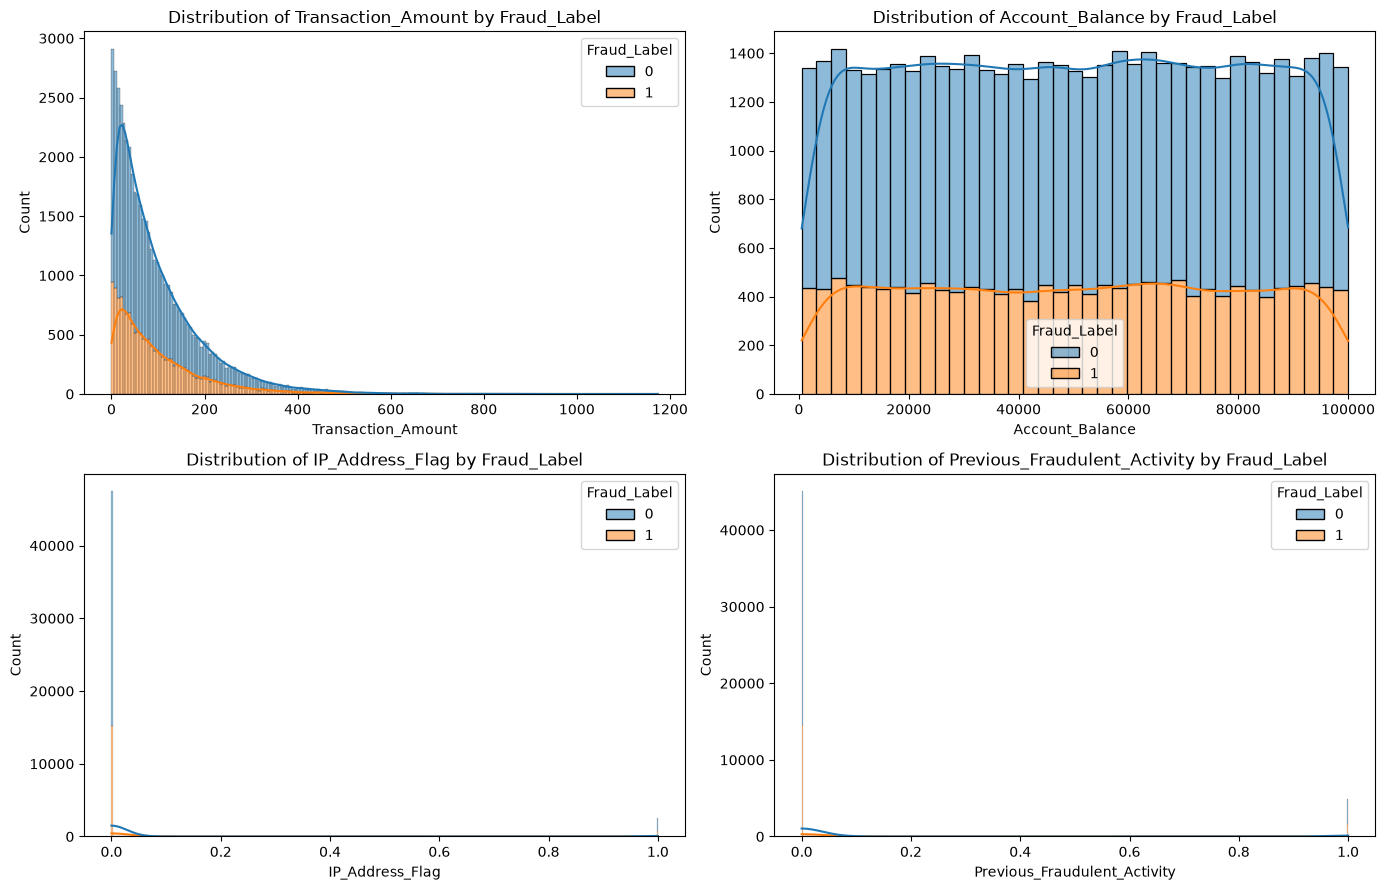

In [8]:

cols = [c for c in df.select_dtypes(include='number').columns
        if c != 'Fraud_Label'][:4]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, col in zip(axes.flatten(), cols):
    sns.histplot(data=df, x=col, kde=True,
                 hue='Fraud_Label', multiple='stack', ax=ax)
    ax.set_title(f'Distribution of {col} by Fraud_Label')

for ax in axes.flatten()[len(cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

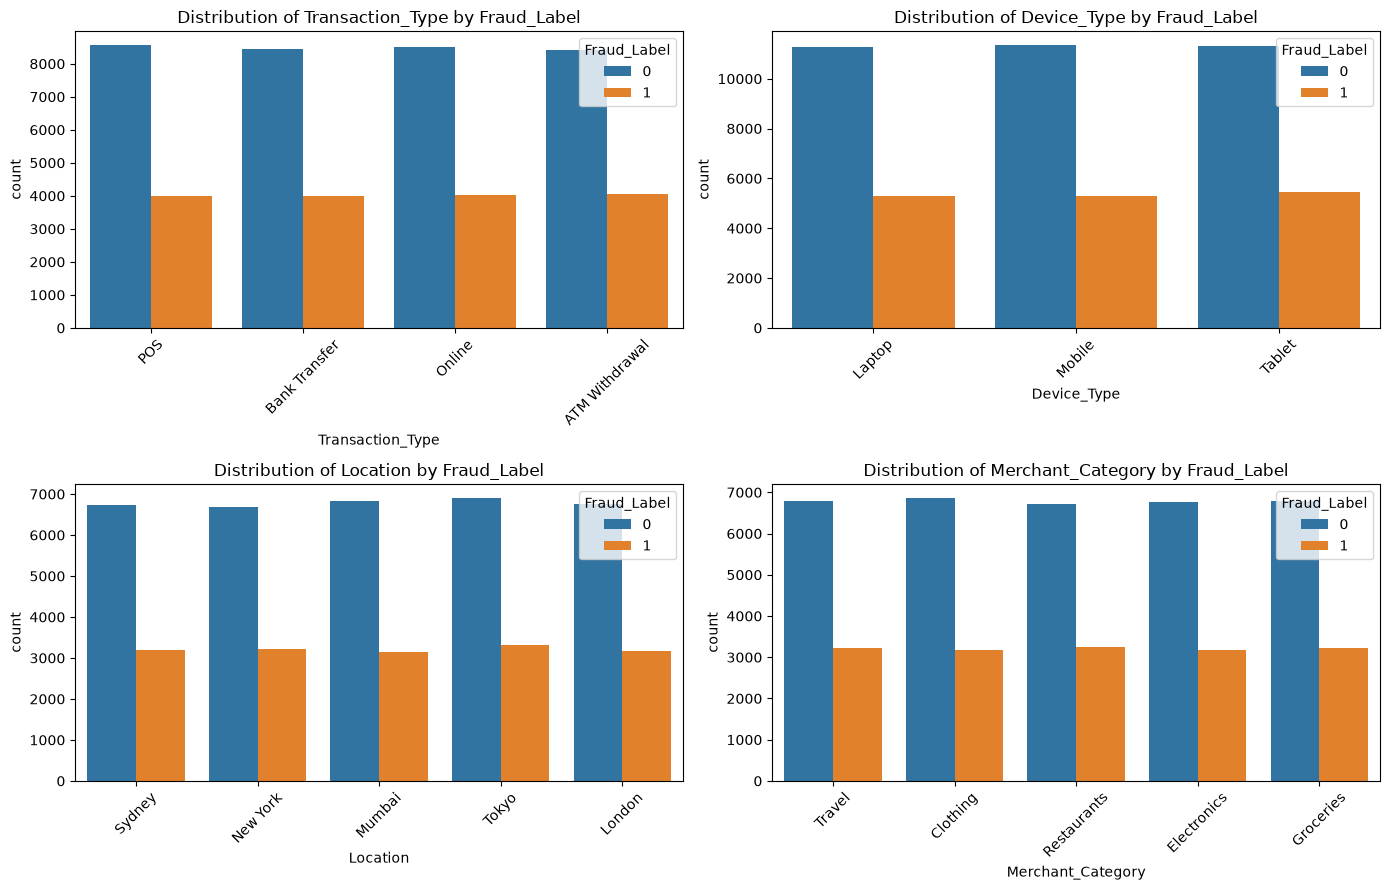

In [9]:
cols = [c for c in df.select_dtypes(include=['object', 'str']).columns
        if c not in excluded_cols][:4]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, col in zip(axes.flatten(), cols):
    sns.countplot(data=df, x=col, hue='Fraud_Label', ax=ax)
    ax.set_title(f'Distribution of {col} by Fraud_Label')
    ax.tick_params(axis='x', rotation=45)

for ax in axes.flatten()[len(cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

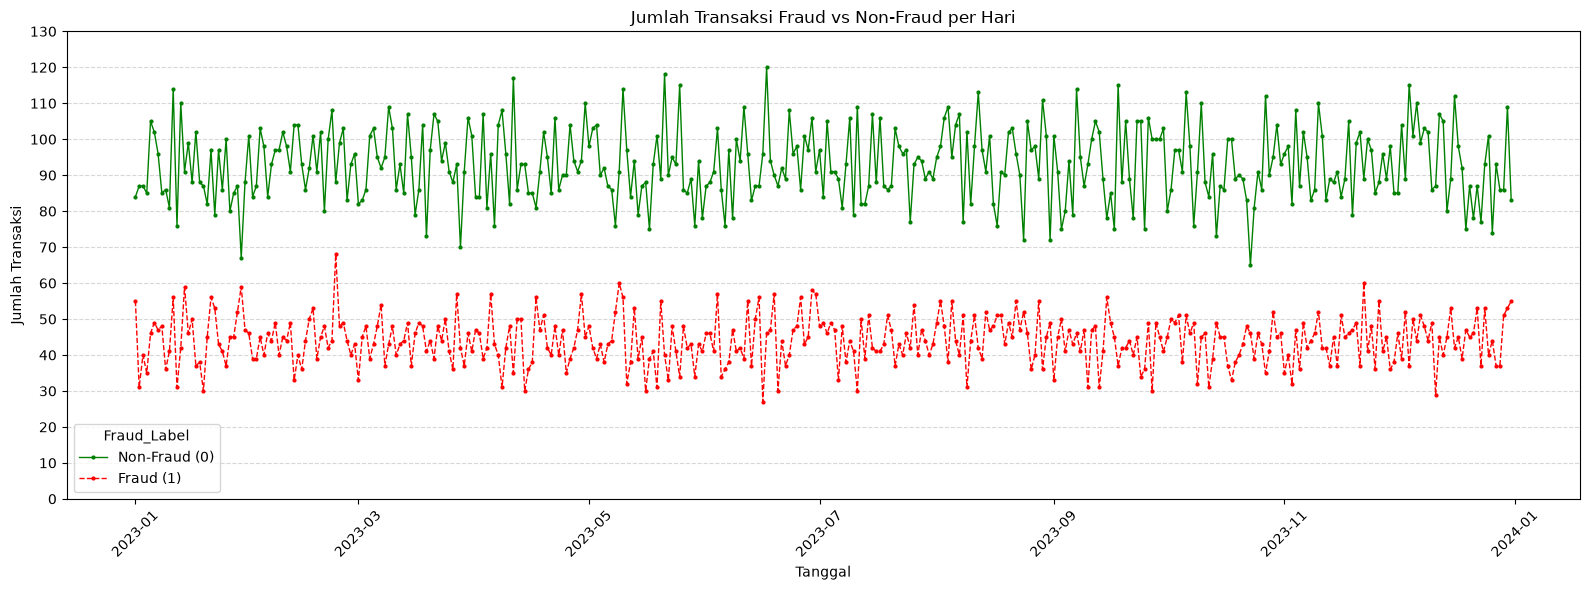

In [10]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

# Hitung jumlah transaksi per hari berdasarkan Fraud_Label
label_counts = (
    df.groupby(
        [df['Timestamp'].dt.date, 'Fraud_Label']
    )
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

# Pastikan kedua label tersedia
if 0 not in label_counts.columns:
    label_counts[0] = 0

if 1 not in label_counts.columns:
    label_counts[1] = 0

# Urutkan kolom
label_counts = label_counts[[0, 1]]

plt.figure(figsize=(16, 6))

# Non-Fraud (0)
plt.plot(
    label_counts.index,
    label_counts[0],
    color='green',
    linestyle='-',
    linewidth=1,
    marker='o',
    markersize=2,
    label='Non-Fraud (0)'
)

# Fraud (1)
plt.plot(
    label_counts.index,
    label_counts[1],
    color='red',
    linestyle='--',
    linewidth=1,
    marker='o',
    markersize=2,
    label='Fraud (1)'
)

plt.title('Jumlah Transaksi Fraud vs Non-Fraud per Hari')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Transaksi')

y_max = int(label_counts[[0, 1]].max().max())
y_limit = ((y_max // 10) + 1) * 10
plt.ylim(0, y_limit)
plt.yticks(range(0, y_limit + 1, 10))

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.5
)

plt.xticks(rotation=45)
plt.legend(title='Fraud_Label')
plt.tight_layout()
plt.show()


Heatmap Korelasi:


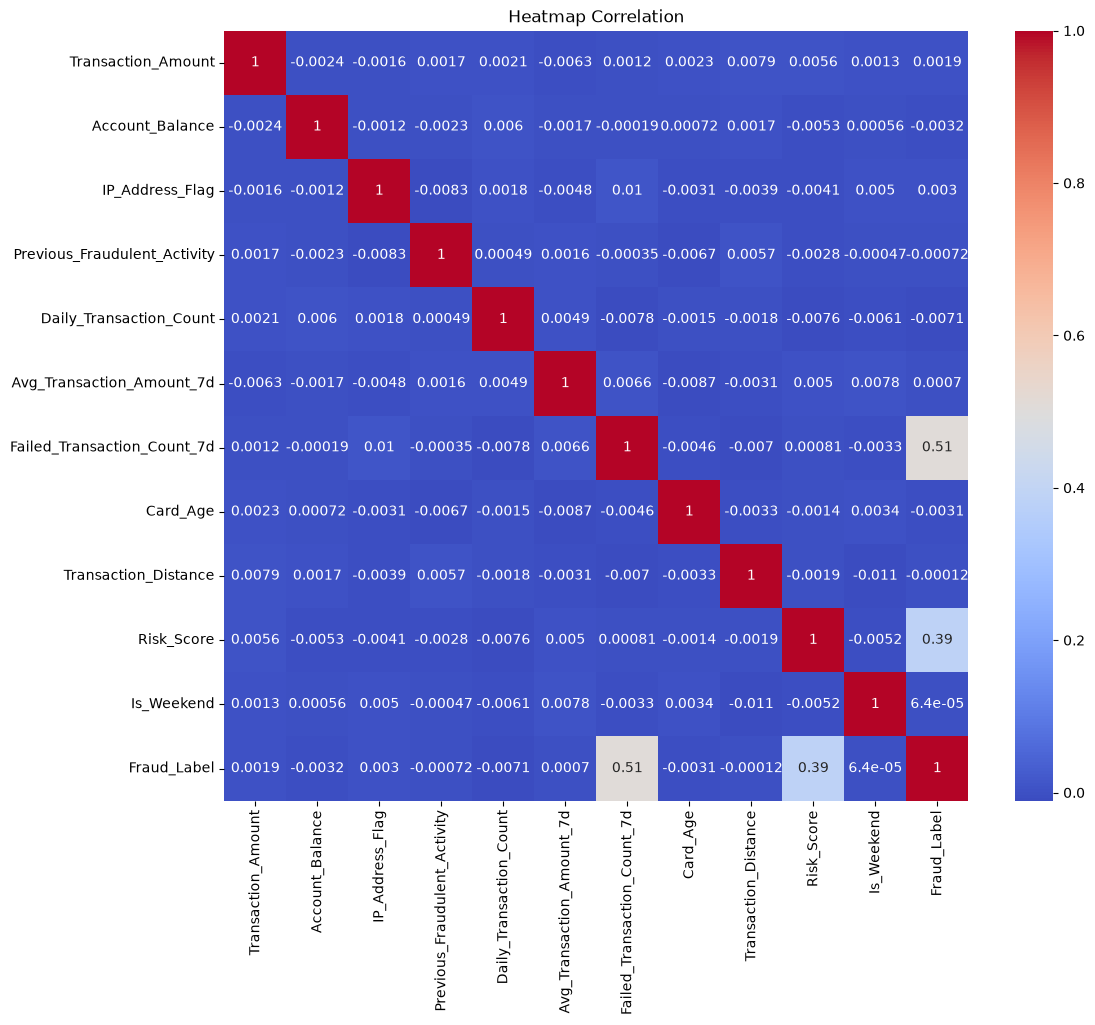

In [11]:
print("\nHeatmap Korelasi:")
corr = df.select_dtypes(include=['number']).corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title('Heatmap Correlation')
plt.show()

In [12]:
excluded_cols = excluded_cols if 'excluded_cols' in locals() else []

print("\nRedundant Values (Duplicate Rows):")
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

print("\nMissing Values:")
missing = df.isnull().sum()
print(missing[missing > 0]) 


Redundant Values (Duplicate Rows):
Number of duplicate rows: 0

Missing Values:
Series([], dtype: int64)



Outlier Detection:
Tidak ada outlier pada kolom Account_Balance
Tidak ada outlier pada kolom Daily_Transaction_Count
Tidak ada outlier pada kolom Avg_Transaction_Amount_7d
Tidak ada outlier pada kolom Failed_Transaction_Count_7d
Tidak ada outlier pada kolom Card_Age
Tidak ada outlier pada kolom Transaction_Distance
Tidak ada outlier pada kolom Risk_Score
Tidak ada outlier pada kolom Is_Weekend


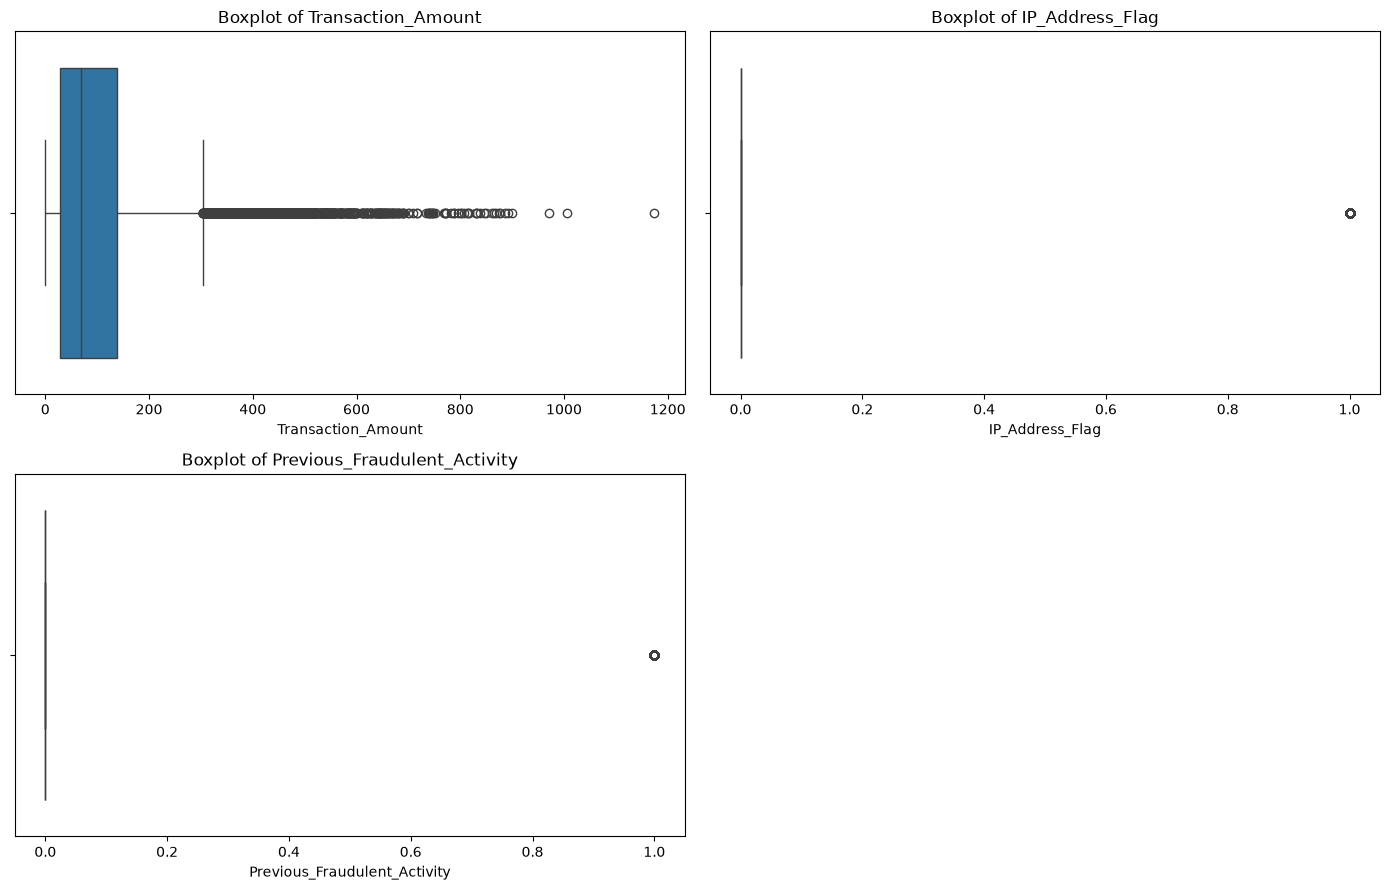

In [13]:
print("\nOutlier Detection:")

outlier_cols = []

for col in df.select_dtypes(include='number').columns:
    if col != 'Fraud_Label':
        Q1, Q3 = df[col].quantile([0.25, 0.75])
        IQR = Q3 - Q1
        lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

        if ((df[col] < lower) | (df[col] > upper)).any():
            outlier_cols.append(col)
        else:
            print(f"Tidak ada outlier pada kolom {col}")

cols = outlier_cols[:4]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, col in zip(axes.flatten(), cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f'Boxplot of {col}')

for ax in axes.flatten()[len(cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [14]:
# Data Cleaning and Preprocessing

# Menghapus Nilai Null
df = df.dropna()

# Menghapus Nilai Duplikat
df = df.drop_duplicates()

# Menghapus Outliers
for col in df.select_dtypes(include='number').columns:
    if col != 'Fraud_Label':
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        df = df.loc[(df[col] >= lower) & (df[col] <= upper)]

# Mengurangi Dimensi Data
drop_cols = [
    'Transaction_ID', 'User_ID', 'Transaction_Type',
    'Account_Balance', 'Previous_Fraudulent_Activity',
    'Device_Type', 'Card_Type', 'Card_Age',
    'Transaction_Distance', 'Is_Weekend'
]

df = df.drop(columns=drop_cols, errors='ignore')

# Melakukan standarisasi teks
for col in df.select_dtypes(include=['object', 'str']).columns:
    if col not in excluded_cols:
        df[col] = df[col].str.lower().str.strip()

In [15]:
# Menampilkan Data Setelah Menghapus Duplikat
print ("\nData After Removing Duplicates:")
print (df.duplicated().sum())


Data After Removing Duplicates:
0


In [16]:
# Menampilkan Data Setelah Menghapus Nilai Null
print ("\nData After Removing Null Values:")
print (df.isnull().sum())


Data After Removing Null Values:
Transaction_Amount             0
Timestamp                      0
Location                       0
Merchant_Category              0
IP_Address_Flag                0
Daily_Transaction_Count        0
Avg_Transaction_Amount_7d      0
Failed_Transaction_Count_7d    0
Authentication_Method          0
Risk_Score                     0
Fraud_Label                    0
dtype: int64


In [17]:
# Menampilkan Data Setelah Dibersihkan
print ("\nData After Cleaning:")
print (df.info())


Data After Cleaning:
<class 'pandas.DataFrame'>
Index: 40851 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   Transaction_Amount           40851 non-null  float64       
 1   Timestamp                    40851 non-null  datetime64[us]
 2   Location                     40851 non-null  str           
 3   Merchant_Category            40851 non-null  str           
 4   IP_Address_Flag              40851 non-null  int64         
 5   Daily_Transaction_Count      40851 non-null  int64         
 6   Avg_Transaction_Amount_7d    40851 non-null  float64       
 7   Failed_Transaction_Count_7d  40851 non-null  int64         
 8   Authentication_Method        40851 non-null  str           
 9   Risk_Score                   40851 non-null  float64       
 10  Fraud_Label                  40851 non-null  int64         
dtypes: datetime64[us](1), float64(3), i

In [18]:
# Data Transformation
df_new = df.copy()

df_new['Timestamp'] = pd.to_datetime(df_new['Timestamp'])
df_new['hour'] = df_new['Timestamp'].dt.hour
df_new['day'] = df_new['Timestamp'].dt.day
df_new['dayofweek'] = df_new['Timestamp'].dt.dayofweek
df_new['is_night'] = df_new['hour'].apply(lambda x: 1 if x < 5 or x >= 22 else 0)

def categorize_part_of_day(hour):
    if 0 <= hour < 6: return 'dinihari'
    elif 6 <= hour < 12: return 'pagi'
    elif 12 <= hour < 18: return 'siang'
    else: return 'malam'

df_new['part_of_day'] = df_new['hour'].apply(categorize_part_of_day)
df_new.drop(columns=['Timestamp'], inplace=True)

df_new.head()

,Transaction_Amount,Location,Merchant_Category,IP_Address_Flag,Daily_Transaction_Count,Avg_Transaction_Amount_7d,Failed_Transaction_Count_7d,Authentication_Method,Risk_Score,Fraud_Label,hour,day,dayofweek,is_night,part_of_day
0,39.79,sydney,travel,0,7,437.63,3,biometric,0.8494,0,19,14,0,0,malam
1,1.19,new york,clothing,0,13,478.76,4,password,0.0959,1,4,7,2,1,dinihari
2,28.96,mumbai,restaurants,0,14,50.01,4,biometric,0.8400,1,15,20,1,0,siang
3,254.32,new york,clothing,0,8,182.48,4,otp,0.7935,1,0,7,3,1,dinihari
5,168.55,tokyo,restaurants,0,3,226.85,2,otp,0.0504,0,20,5,0,0,malam


In [19]:
# Split Data
X = df_new.drop('Fraud_Label', axis=1)
y = df_new['Fraud_Label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [20]:
numerical_cols = X_train.select_dtypes(include=['number']).columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object','str']).columns.tolist()

In [21]:
joblib.dump(numerical_cols, 'numerical_cols.pkl')
joblib.dump(categorical_cols, 'categorical_cols.pkl')

['categorical_cols.pkl']

In [23]:
scaler = StandardScaler()
X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

In [24]:
joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']

In [26]:
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

X_train[categorical_cols] = encoder.fit_transform(
    X_train[categorical_cols].astype(str)
)

X_test[categorical_cols] = encoder.transform(
    X_test[categorical_cols].astype(str)
)

In [27]:
joblib.dump(encoder, 'encoder.pkl')

['encoder.pkl']

In [28]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

In [29]:
rf = RandomForestClassifier(
    random_state=42
)
rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [30]:
joblib.dump(rf, 'model.pkl')
joblib.dump(X_test, 'X_Test.pkl')
joblib.dump(y_test, 'y_Test.pkl')

['y_Test.pkl']

In [31]:
y_pred = rf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

from sklearn.metrics import classification_report
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 1.0

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      5547
           1       1.00      1.00      1.00      2624

    accuracy                           1.00      8171
   macro avg       1.00      1.00      1.00      8171
weighted avg       1.00      1.00      1.00      8171



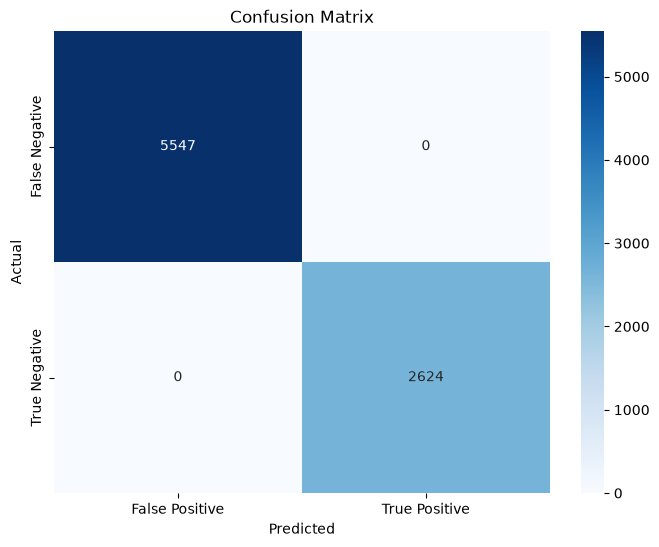

In [32]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['False Positive', 'True Positive'],
            yticklabels=['False Negative', 'True Negative'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

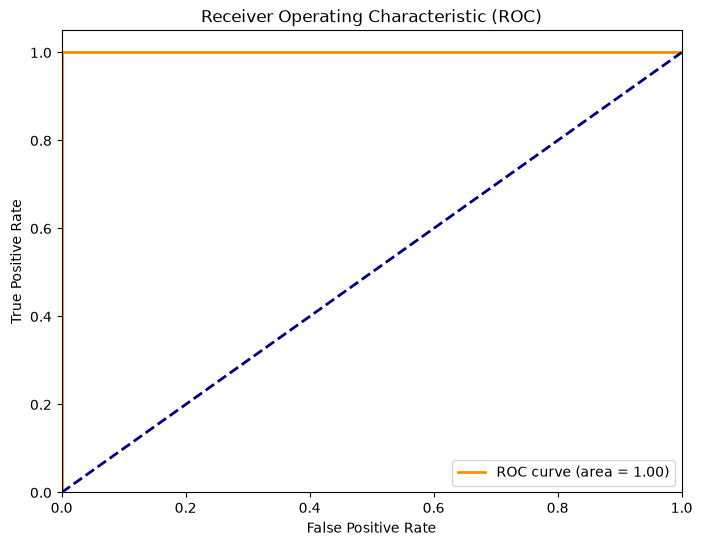

In [33]:
y_pred_proba = rf.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim((0.0, 1.0))
plt.ylim((0.0, 1.05))
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()